In [1]:
import os
import zipfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)


## 4. Download and load the dataset

In [2]:
# Download the public UCI dataset ZIP file.
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"

if not os.path.exists(zip_path):
    urllib.request.urlretrieve(url, zip_path)

# Extract the downloaded ZIP file.
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("sms_dataset")

# The dataset file contains a label and a message separated by tabs.
file_path = "sms_dataset/SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep="\\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset shape:", df.shape)
display(df.head())


/tmp/ipykernel_4149/2493000895.py:15: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(


Dataset shape: (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 5. Explore the dataset

In [3]:
print("Missing values:")
print(df.isnull().sum())

print("\\nClass counts:")
display(df["label"].value_counts())

print("\\nDataset information:")
df.info()


Missing values:
label      0
message    0
dtype: int64
\nClass counts:


,count
label,
ham,4827
spam,747


\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5574 non-null   object
 1   message  5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


## 6. Visualize the class distribution

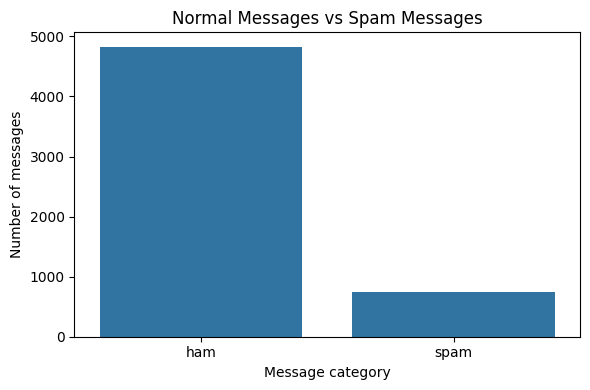

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label", order=["ham", "spam"])
plt.title("Normal Messages vs Spam Messages")
plt.xlabel("Message category")
plt.ylabel("Number of messages")
plt.tight_layout()
plt.show()


## 7. Select input text and target label

In [5]:
# X contains the SMS text; y contains its category.
X = df["message"]
y = df["label"]

print("Input example:")
print(X.iloc[0])

print("\\nTarget example:")
print(y.iloc[0])


Input example:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
\nTarget example:
ham


## 8. Split data into training and testing sets

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))


Training messages: 4459
Testing messages: 1115


## 9. Build the text classification pipeline

Computers cannot directly learn from raw sentences. `TfidfVectorizer` converts words into numerical features. Logistic Regression then learns patterns that help distinguish spam from normal messages.

We keep vectorization inside the pipeline so it is fitted using training messages only.

In [7]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model training completed.")


Model training completed.


## 10. Make predictions

In [8]:
# Predict whether each test message is ham or spam.
y_pred = model.predict(X_test)

print("First 10 actual labels:")
print(y_test.iloc[:10].to_list())

print("\\nFirst 10 predicted labels:")
print(y_pred[:10])


First 10 actual labels:
['ham', 'ham', 'ham', 'spam', 'ham', 'ham', 'spam', 'ham', 'ham', 'ham']
\nFirst 10 predicted labels:
['ham' 'ham' 'ham' 'spam' 'ham' 'ham' 'spam' 'ham' 'ham' 'ham']


## 11. Evaluate model performance

In [9]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="spam", zero_division=0)
recall = recall_score(y_test, y_pred, pos_label="spam", zero_division=0)
f1 = f1_score(y_test, y_pred, pos_label="spam", zero_division=0)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (spam)", "Recall (spam)", "F1-score (spam)"],
    "Score": [accuracy, precision, recall, f1]
})

display(results.round(4))

print(classification_report(
    y_test,
    y_pred,
    labels=["ham", "spam"],
    target_names=["Not spam", "Spam"],
    zero_division=0
))


,Metric,Score
0,Accuracy,0.9740
1,Precision (spam),1.0000
2,Recall (spam),0.8054
3,F1-score (spam),0.8922


              precision    recall  f1-score   support

    Not spam       0.97      1.00      0.99       966
        Spam       1.00      0.81      0.89       149

    accuracy                           0.97      1115
   macro avg       0.99      0.90      0.94      1115
weighted avg       0.97      0.97      0.97      1115



## 12. Display the confusion matrix

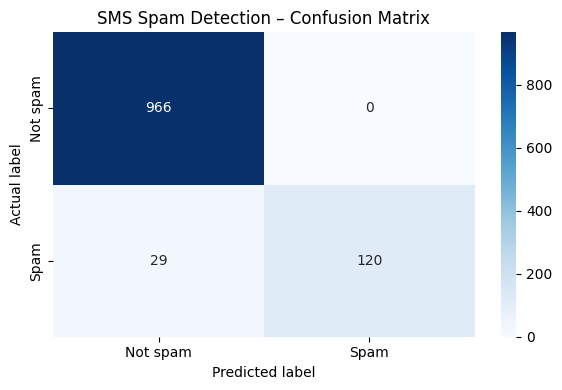

Confusion matrix:
[[966   0]
 [ 29 120]]


In [11]:
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not spam", "Spam"],
    yticklabels=["Not spam", "Spam"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("SMS Spam Detection – Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)


## 13. Test your own SMS messages

In [10]:
sample_messages = [
    "Congratulations! You have won a free prize. Call now to claim.",
    "Hi, are we meeting for the project discussion today?"
]

sample_predictions = model.predict(sample_messages)
sample_probabilities = model.predict_proba(sample_messages)

for message, prediction, probabilities in zip(
    sample_messages, sample_predictions, sample_probabilities
):
    print("Message:", message)
    print("Prediction:", "SPAM" if prediction == "spam" else "NOT SPAM")
    print("Spam probability:", round(probabilities[list(model.classes_).index("spam")], 4))
    print("-" * 60)


Message: Congratulations! You have won a free prize. Call now to claim.
Prediction: SPAM
Spam probability: 0.9369
------------------------------------------------------------
Message: Hi, are we meeting for the project discussion today?
Prediction: NOT SPAM
Spam probability: 0.0429
------------------------------------------------------------
